<a href="https://colab.research.google.com/github/RashidTheDS/Convolutional-Neural-Network-CNN-/blob/main/Filters_in_Convolutional_Neural_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In Convolutional Neural Networks, Filters detect spatial patterns such as edges in an image by detecting the changes in intensity values of the image.

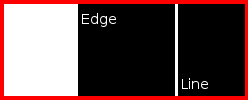

In terms of an image, a *high-frequency image* is the one where the intensity of the pixels changes by a large amount, whereas a *low-frequency image* is the one where the intensity is almost uniform. Usually, an image has both high and low frequency components. The high-frequency components correspond to the edges of an object because at the edges the rate of change of intensity of pixel values is high.

**High pass filters** are used to enhance the high-frequency parts of an image.

Let’s take an example that a part of your image has pixel values as [[10, 10, 0], [10, 10, 0], [10, 10, 0]] indicating the image pixel values are decreasing toward the right i.e. the image changes from light at the left to dark at the right. The filter used here is [[1, 0, -1], [1, 0, -1], [1, 0, -1]].

Now, we take the convolutional of these two matrices that give the output [[10, 0, 0], [10, 0, 0], [10, 0, 0]]. Finally, these values are summed up to give a pixel value of 30, which gives the variation in pixel values as we move from left to right. Similarly, we find the subsequent pixel values.

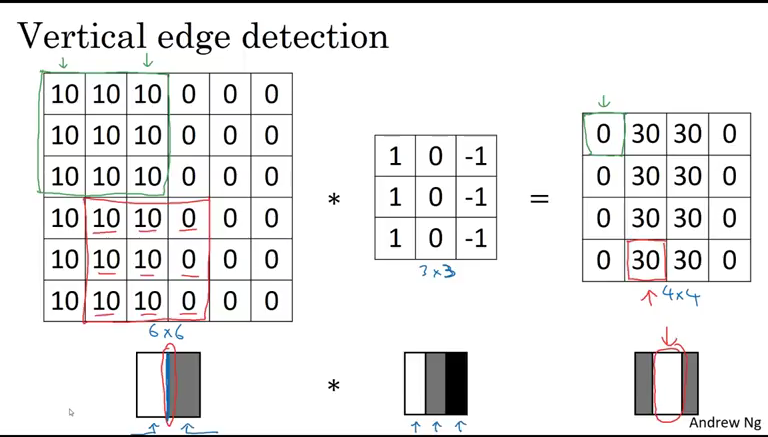

Here, you will notice that a rate of change of pixel values varies a lot from left to right thus a vertical edge has been detected. Had you used the filter [[1, 1, 1], [0, 0, 0], [-1, -1, -1]], you would get the convolutional output consisting of 0s only i.e. no horizontal edge present. In the similar ways, [[-1, 1], [-1, 1]] detects a vertical edge.

Usually, a vertical edge detection filter has bright pixels on the left and dark pixels on the right (or vice-versa). Also, the sum of values of the filter should be 0 *else* the resultant image will become brighter or darker.

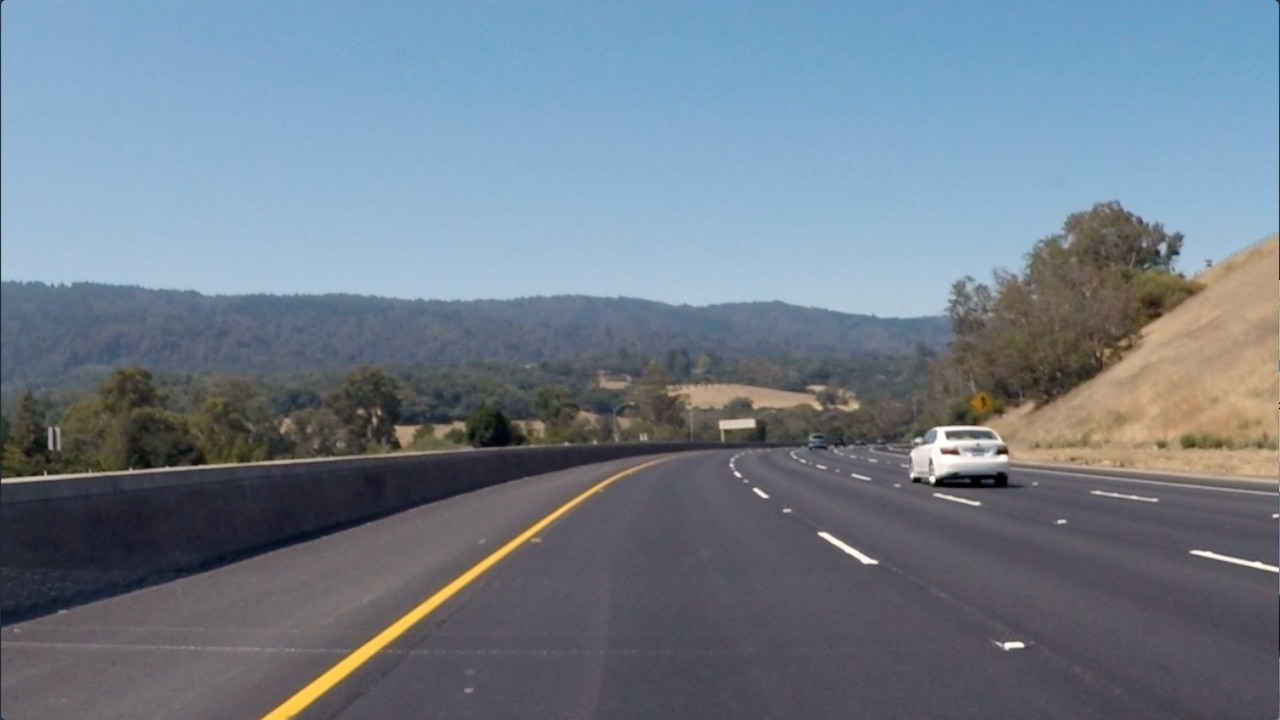


# **Implementation**

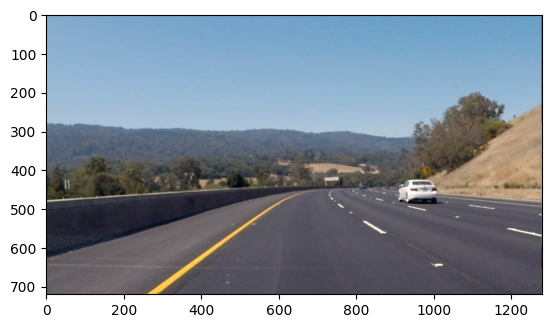

In [2]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2
import numpy as np

# Read in the image
image = mpimg.imread('edge_detection_ex.jpg')
plt.imshow(image)

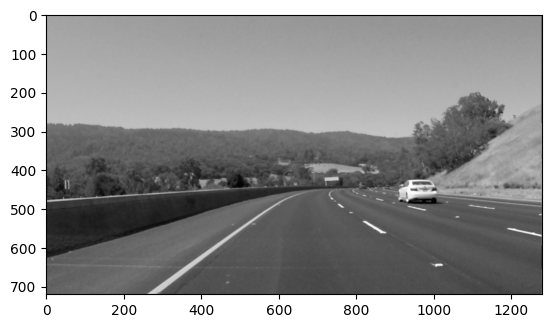

In [3]:
# Convert to grayscale for filtering
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
plt.imshow(gray, cmap='gray') # reuires color information so we pass cmap='gray'

One good example of edge detection filter is **Sobel filter**. Let’s implement that for edge detection.

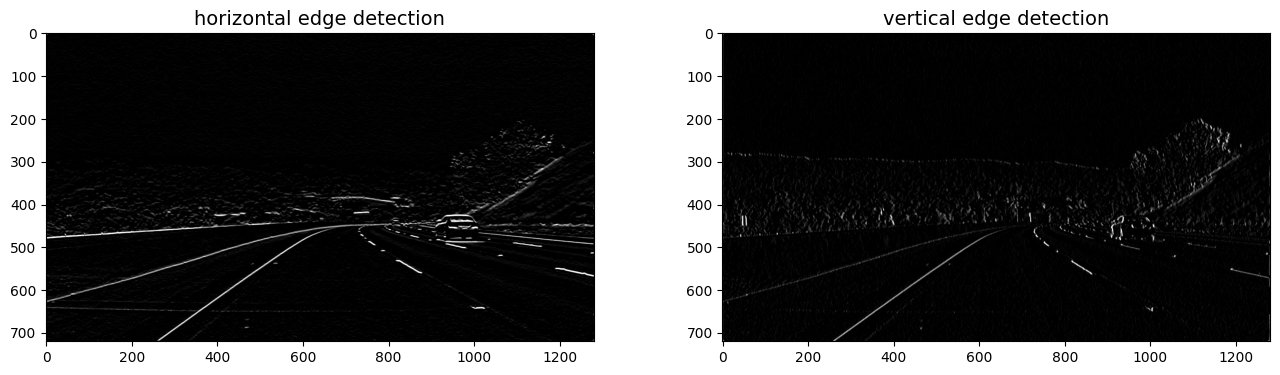

In [4]:
# 3x3 sobel filter for horizontal edge detection
sobel_y = np.array([[-1, -2, -1],
                    [0, 0, 0],
                    [1, 2, 1]])
# vertical edge detection
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])
# filter the image using filter2D(grayscale image, bit-depth, kernel)
filtered_image1 = cv2.filter2D(gray, -1, sobel_y)
filtered_image2 = cv2.filter2D(gray, -1, sobel_x)
f, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].set_title('horizontal edge detection', fontsize=14)
ax[0].imshow(filtered_image1, cmap='gray')
ax[1].set_title('vertical edge detection', fontsize=14)
ax[1].imshow(filtered_image2, cmap='gray')

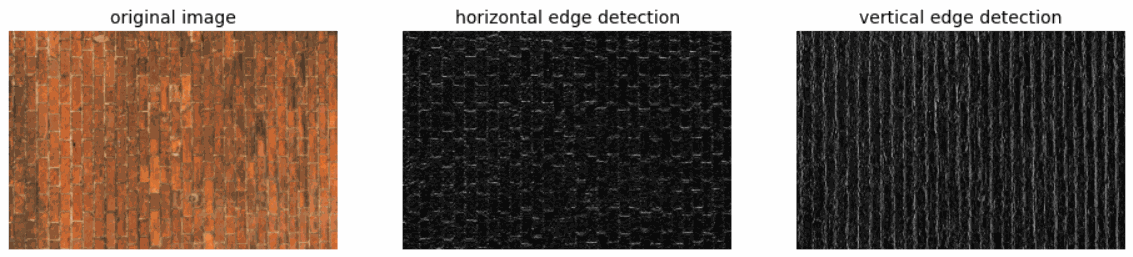

**Note**: In convolutional neural networks, the filters are learned the same way as hyperparameters through backpropagation during the training process.

**References:**

1. Edge detection - Andrew Ng
2. Line and edge in image detection - StackOverflow
3. Sobel operator - Wikipedia